## 네트워크 데이터 분석: ego-Facebook

### 1. 데이터 및 분석 환경
- 데이터셋: SNAP ego-Facebook (facebook_combined.txt.gz)
- 출처: https://snap.stanford.edu/data/ego-Facebook.html
- 내용: Facebook 사용자 4,039명, 친구 관계 88,234개
- 그래프 종류: 무방향(Undirected) 그래프, 가중치 없음
  - 친구 관계는 양쪽이 서로 맺는 관계라서 방향이 없음
  - 데이터에 관계의 강도 정보가 없어서 가중치를 반영하지 않음
- 분석 환경: macOS, 라이브러리 버전은 아래 코드 참고

In [1]:
import sys, platform
import networkx as nx
import community as community_louvain
import matplotlib, pandas, pyvis

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("networkx:", nx.__version__)
print("matplotlib:", matplotlib.__version__)
print("pandas:", pandas.__version__)
print("pyvis:", pyvis.__version__)

Python: 3.9.6
OS: macOS-27.0.1-arm64-arm-64bit
networkx: 3.2.1
matplotlib: 3.9.4
pandas: 2.3.3
pyvis: 0.3.2


### 2. 데이터 로딩 및 그래프 구성

In [2]:
G = nx.read_edgelist('facebook_combined.txt.gz', nodetype=int)

print("노드 수:", G.number_of_nodes())
print("엣지 수:", G.number_of_edges())
print("방향 그래프인가?:", G.is_directed())
print("평균 친구 수:", round(2 * G.number_of_edges() / G.number_of_nodes(), 2))

노드 수: 4039
엣지 수: 88234
방향 그래프인가?: False
평균 친구 수: 43.69


### 3. 중심성 분석
Degree, PageRank, Betweenness 중심성을 계산하고 상위 10개 노드를 비교함.
- Betweenness는 노드가 많아 계산이 오래 걸리므로, 노드 500개를 표본으로 근사 계산함. (k=500).

In [5]:
import pandas as pd

degree = nx.degree_centrality(G)
pagerank = nx.pagerank(G)
betweenness = nx.betweenness_centrality(G, k=500, seed=42)

def top10(scores):
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)[:10]

table = pd.DataFrame({
    '순위': range(1, 11),
    'Degree 노드': [n for n, s in top10(degree)],
    'Degree 값': [round(s, 4) for n, s in top10(degree)],
    'PageRank 노드': [n for n, s in top10(pagerank)],
    'PageRank 값': [round(s, 4) for n, s in top10(pagerank)],
    'Betweenness 노드': [n for n, s in top10(betweenness)],
    'Betweenness 값': [round(s, 4) for n, s in top10(betweenness)],
})
table

,순위,Degree 노드,Degree 값,PageRank 노드,PageRank 값,Betweenness 노드,Betweenness 값
0,1,107,0.2588,3437,0.0076,107,0.4898
1,2,1684,0.1961,107,0.0069,1684,0.3446
2,3,1912,0.1870,1684,0.0064,3437,0.2223
3,4,3437,0.1355,0,0.0063,1912,0.2164
4,5,0,0.0859,1912,0.0039,0,0.1615
5,6,2543,0.0728,348,0.0023,1085,0.1500
6,7,2347,0.0721,686,0.0022,698,0.1136
7,8,1888,0.0629,3980,0.0022,567,0.0882
8,9,1800,0.0607,414,0.0018,58,0.0828
9,10,1663,0.0582,698,0.0013,428,0.0607


#### 중심성 분석 해석
- 107, 1684, 3437, 1912, 0번 노드는 세 지표 모두에서 상위권에 있어 이 네트워크의 핵심 허브로 볼 수 있음.
- 107번은 Degree와 Betweenness 모두 1위로, 친구가 가장 많으면서 서로 다른 그룹을 이어주는 다리 역할도 함.
- PageRank 1위는 3437번으로, 친구 수는 107번보다 적지만 영향력 있는 친구들과 연결되어 있음.
- 일부 노드는 한 지표에서만 상위권에 있어, 지표마다 "중요함"의 기준이 다르다는 것을 확인할 수 있음.

### 4. 커뮤니티 탐지 (Louvain)

In [6]:
from collections import Counter

partition = community_louvain.best_partition(G, random_state=42)

comm_size = Counter(partition.values())
print("커뮤니티 수:", len(comm_size))
print("모듈성(Modularity):", round(community_louvain.modularity(partition, G), 4))

comm_table = pd.DataFrame(comm_size.most_common(), columns=['커뮤니티 번호', '노드 수'])
comm_table

커뮤니티 수: 15
모듈성(Modularity): 0.8349


,커뮤니티 번호,노드 수
0,10,548
1,2,535
2,4,442
3,9,432
4,1,430
5,0,354
6,6,323
7,12,237
8,8,226
9,5,206


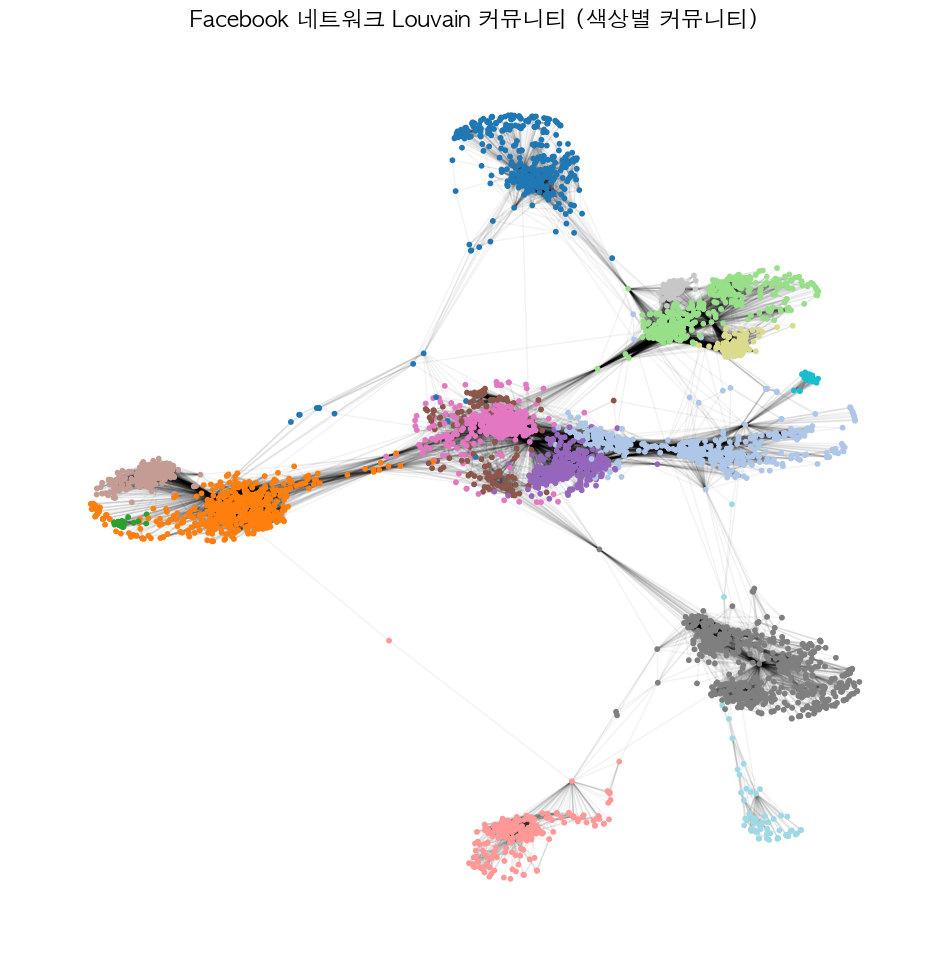

In [8]:
plt.rcParams['font.family'] = 'AppleGothic'
import matplotlib.pyplot as plt

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(12, 12))
nx.draw_networkx_nodes(G, pos, node_size=10,
                       node_color=list(partition.values()), cmap='tab20')
nx.draw_networkx_edges(G, pos, alpha=0.05)
plt.title('Facebook 네트워크 Louvain 커뮤니티 (색상별 커뮤니티)', fontsize=16)
plt.axis('off')
plt.savefig('community.png', dpi=150)
plt.savefig('community.pdf')
plt.show()

#### 4-1. 주요 커뮤니티 특성

In [10]:
rows = []
for comm_id, size in comm_size.most_common(5):
    members = [n for n in partition if partition[n] == comm_id]
    sub = G.subgraph(members)
    hub = max(members, key=lambda n: degree[n])
    rows.append({
        '커뮤니티': comm_id,
        '노드 수': size,
        '내부 밀도': round(nx.density(sub), 4),
        '대표 허브 노드': hub,
        '허브의 친구 수': G.degree(hub),
    })

pd.DataFrame(rows)

,커뮤니티,노드 수,내부 밀도,대표 허브 노드,허브의 친구 수
0,10,548,0.0357,3437,547
1,2,535,0.0608,1684,792
2,4,442,0.1189,1912,755
3,9,432,0.1791,107,1045
4,1,430,0.0659,483,231


##### 커뮤니티 탐지 결과
- Louvain 알고리즘으로 총 15개의 커뮤니티를 찾았고, 모듈성은 약 0.83으로 그룹이 뚜렷하게 나뉨.
- 커뮤니티 크기는 19명에서 548명까지 차이가 큼.
- 상위 커뮤니티들의 대표 허브가 중심성 분석의 핵심 노드(3437, 1684, 1912, 107)와 겹침.
  ego-Facebook 데이터는 몇몇 사용자의 친구 목록을 모아 만든 것이라, 각 허브를 중심으로 친구 그룹이 형성된 것으로 보임.
- 커뮤니티 10은 548명으로 가장 크지만 내부 밀도가 0.036으로 가장 낮다. 허브 3437과는 거의 모두 연결돼 있지만 구성원끼리는 서로 잘 모르는, 한 사람 중심의 느슨한 그룹임.
- 커뮤니티 9는 내부 밀도가 0.179로 가장 높아 구성원끼리 서로 많이 아는 끈끈한 그룹임.

### 5. 부분 네트워크(Ego-Network) 분석
세 중심성 지표에서 모두 상위권인 107, 1684, 3437, 1912, 0번 노드를 핵심 노드로 선정했습니다.

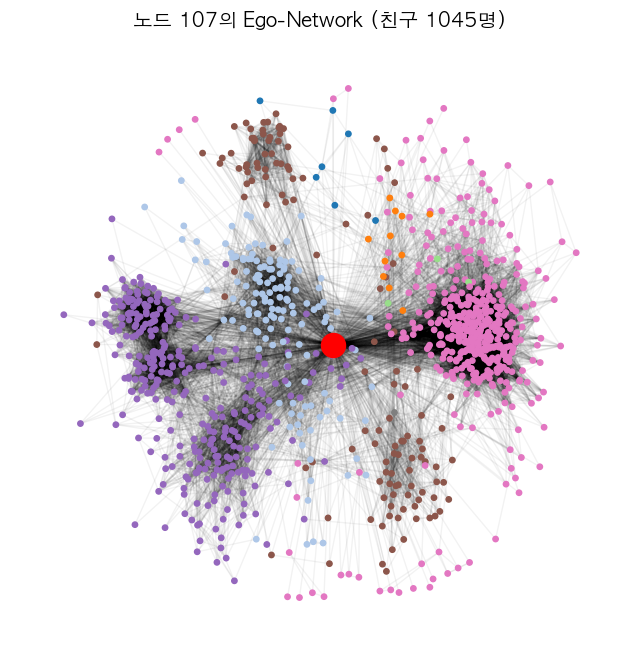

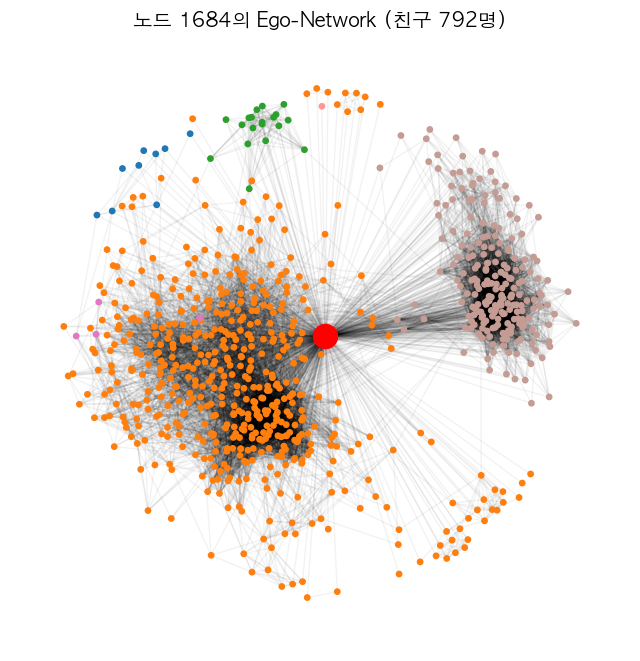

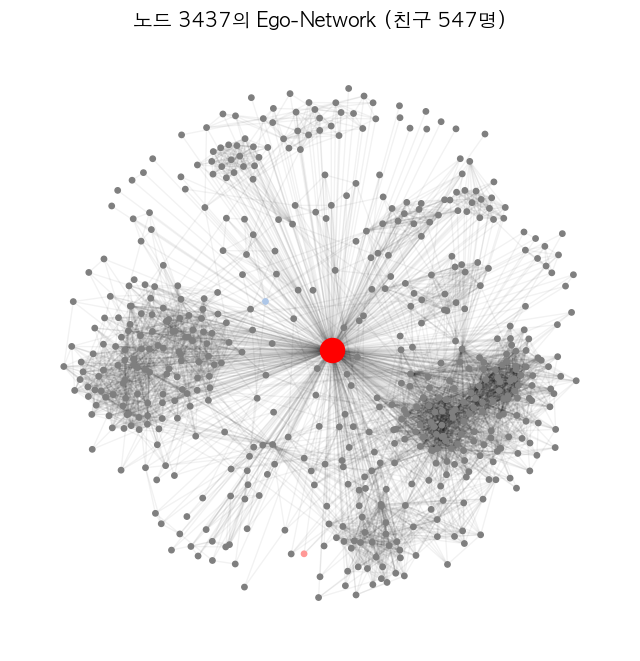

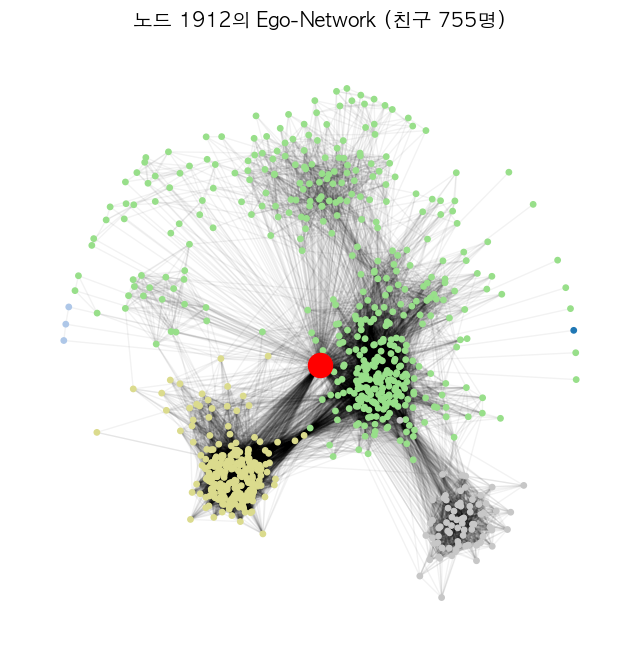

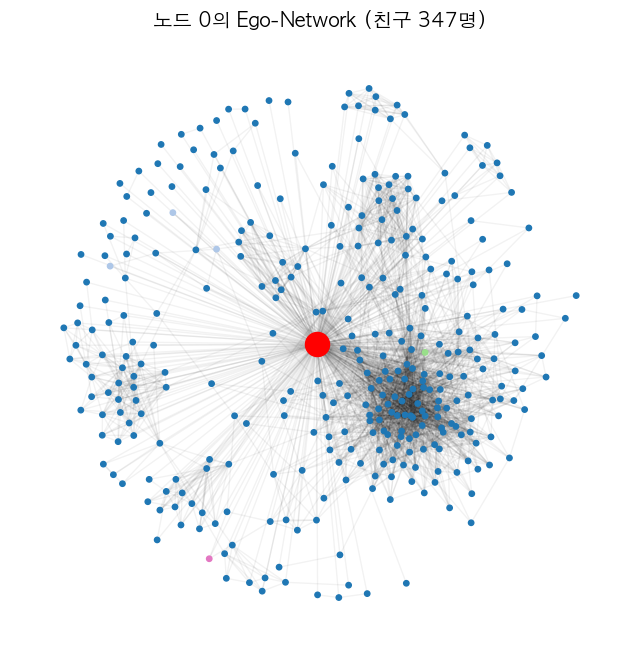

In [12]:
key_nodes = [107, 1684, 3437, 1912, 0]

for node in key_nodes:
    ego = nx.ego_graph(G, node)
    ego_pos = nx.spring_layout(ego, seed=42)

    colors = ['red' if n == node else partition[n] for n in ego.nodes()]
    neighbors = [n for n in ego.nodes() if n != node]

    plt.figure(figsize=(8, 8))
    nx.draw_networkx_edges(ego, ego_pos, alpha=0.05)
    nx.draw_networkx_nodes(ego, ego_pos, nodelist=neighbors, node_size=15,
                           node_color=[partition[n] for n in neighbors],
                           cmap='tab20', vmin=0, vmax=14)
    nx.draw_networkx_nodes(ego, ego_pos, nodelist=[node], node_size=300,
                           node_color='red')
    plt.title(f'노드 {node}의 Ego-Network (친구 {len(neighbors)}명)', fontsize=14)
    plt.axis('off')
    plt.savefig(f'ego_{node}.png', dpi=150)
    plt.show()

In [13]:
rows = []
for node in key_nodes:
    ego = nx.ego_graph(G, node)
    friends = ego.copy()
    friends.remove_node(node)
    rows.append({
        '노드': node,
        '친구 수': G.degree(node),
        '친구들끼리 밀도': round(nx.density(friends), 4),
        '친구들이 속한 커뮤니티 수': len(set(partition[n] for n in friends)),
        '핵심 노드를 빼면 나뉘는 그룹 수': nx.number_connected_components(friends),
    })

pd.DataFrame(rows)

,노드,친구 수,친구들끼리 밀도,친구들이 속한 커뮤니티 수,핵심 노드를 빼면 나뉘는 그룹 수
0,107,1045,0.0490,8,12
1,1684,792,0.0448,6,10
2,3437,547,0.0322,3,15
3,1912,755,0.1055,5,10
4,0,347,0.0420,4,19


### Ego-Network 해석
| 노드 | 친구 수 | 친구들끼리 밀도 | 커뮤니티 수 | 빼면 나뉘는 그룹 수 |
|---|---|---|---|---|
| 107 | 1045 | 0.049 | 8 | 12 |
| 1684 | 792 | 0.045 | 6 | 10 |
| 3437 | 547 | 0.032 | 3 | 15 |
| 1912 | 755 | 0.106 | 5 | 10 |
| 0 | 347 | 0.042 | 4 | 19 |

- 107번: 친구가 가장 많고, 친구들이 8개 커뮤니티에 퍼져 있다. 여러 그룹을 이어주는 다리 역할로, Betweenness 1위인 이유와 일치함.
- 1684번: 6개 커뮤니티에 걸쳐 있어 107번과 비슷한 연결자 역할을 함.
- 3437번: 친구들이 3개 커뮤니티에만 모여 있고 친구들끼리 밀도도 가장 낮다. 다양한 그룹을 잇기보다 한 그룹의 중심에 있는 허브임.
- 1912번: 친구들끼리 밀도가 0.106으로 가장 높아, 친구들끼리도 서로 잘 아는 끈끈한 그룹의 중심임.
- 0번: 친구 수는 가장 적지만 빼면 친구들이 19개 그룹으로 쪼개진다. 서로 모르는 친구들을 이 사람 혼자 연결하고 있다는 뜻임.

### 6. Pyvis 인터랙티브 시각화
0번 노드의 Ego-Network를 커뮤니티별 색상으로 표시함.
전체 네트워크는 엣지가 많아 브라우저에서 느려지므로 부분 네트워크를 사용함.

In [15]:
from pyvis.network import Network

ego0 = nx.ego_graph(G, 0)
net = Network(height='750px', width='100%', bgcolor='white', cdn_resources='in_line')

for n in ego0.nodes():
    net.add_node(n, label=str(n), group=partition[n],
                 size=30 if n == 0 else 8,
                 title=f'노드 {n} / 커뮤니티 {partition[n]} / 친구 {G.degree(n)}명')

for u, v in ego0.edges():
    net.add_edge(u, v)

net.write_html('ego_0_interactive.html')
print("저장 완료: ego_0_interactive.html")

저장 완료: ego_0_interactive.html


### 7. 결론
- 107, 1684, 3437, 1912, 0번 노드가 Degree, PageRank, Betweenness에서 모두 상위권이었고, 이들은 각 커뮤니티의 대표 허브와도 겹쳤다.
- Louvain으로 15개 커뮤니티를 찾았고 모듈성이 약 0.83으로 높아, 친구 관계가 뚜렷한 그룹 단위로 형성되어 있음을 확인했다.
- 같은 허브라도 역할이 달랐다. 107번은 여러 커뮤니티를 잇는 연결자, 3437번은 한 그룹의 중심, 1912번은 끈끈한 그룹의 중심이었다.
- 친구 수가 많다고 다리 역할을 하는 것은 아니며, 여러 중심성 지표를 함께 봐야 노드의 역할을 제대로 이해할 수 있다.